# Baseline vs Adaptive — β = 0.7

First-pass exploration of the campaign data:

- 7 scenarios (clean + A–F), 240 s each, **n = 1 per scenario per mode**.
- `baseline` = fixed bitrate at the negotiated target (~19 Mbps).
- `adaptive` = rule-based AIMD controller (β = 0.7, γ = 1.15, RTT threshold = 100 ms, hysteresis = 2000 ms, stable_time = 7500 ms, step = 500 kbps).

Single-run methodology is documented in `idea-10-abr-comparison.md`. With n = 1, we read large effects as real and small effects as suggestive; the subjective ratings (`.notes.txt`) serve as a second axis that does not need replication.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('../../results')
BASELINE_DIR = RESULTS_DIR / 'baseline'
ADAPTIVE_DIR = RESULTS_DIR / 'adaptive'

SCENARIOS = ['clean', 'A', 'B', 'C', 'D', 'E', 'F']
TARGET_KBPS = 18988  # negotiated encoder target
RTT_THRESHOLD_MS = 100  # C³G's RTVL_th, also our abr_rtt_threshold_ms

# `tc htb` cap schedules — mirror testbed/lib/scenarios.sh. (time_s, cap_mbps).
# FREE = effectively unshaped (we plot 25 as a visual ceiling).
FREE_MBPS = 25
SCENARIO_CAPS = {
    'clean': [(0, FREE_MBPS)],
    'A':     [(0, FREE_MBPS), (80, 8),   (160, FREE_MBPS)],
    'B':     [(0, FREE_MBPS), (60, 16),  (100, 12), (140, 8),  (160, FREE_MBPS)],
    'C':     [(0, FREE_MBPS), (40, 14),  (120, 10), (200, FREE_MBPS)],
    'D':     [(0, FREE_MBPS), (30, 10),  (60, FREE_MBPS), (90, 10), (120, FREE_MBPS), (150, 10), (180, FREE_MBPS), (210, 10)],
    'E':     [(0, FREE_MBPS), (40, 4),   (200, FREE_MBPS)],
    'F':     [(0, 6), (160, FREE_MBPS)],
}

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 150, 'figure.figsize': (10, 4)})

## 1. Load all CSVs and notes

We discover the matching file per scenario by prefix (`<scenario>_run0_*.csv`). The notes file carries the subjective ratings collected by `run_scenario.sh`.

In [2]:
def find_run(directory: Path, scenario: str):
    """Return the (csv_path, notes_path) for this scenario's run 0, or (None, None)."""
    csvs = sorted(directory.glob(f'{scenario}_run0_*.csv'))
    if not csvs:
        return None, None
    csv = csvs[-1]  # latest if multiple
    notes = csv.with_suffix('').with_suffix('.notes.txt')
    if not notes.exists():
        # filename pattern is X_run0_TS.notes.txt (two suffixes)
        notes = csv.parent / (csv.stem + '.notes.txt')
    return csv, notes if notes.exists() else None


def parse_notes(path: Path) -> dict:
    if path is None:
        return {}
    out = {}
    for line in path.read_text().splitlines():
        m = re.match(r'^(\w+):\s*(.+)$', line)
        if m:
            out[m.group(1)] = m.group(2).strip()
    return out


def load(mode_dir: Path):
    """Returns {scenario: {'df': DataFrame, 'notes': dict}}"""
    out = {}
    for s in SCENARIOS:
        csv_path, notes_path = find_run(mode_dir, s)
        if csv_path is None:
            print(f'  missing {s} in {mode_dir.name}')
            continue
        df = pd.read_csv(csv_path)
        df['elapsed_s'] = df['elapsed_ms'] / 1000.0
        out[s] = {'df': df, 'notes': parse_notes(notes_path)}
    return out


baseline = load(BASELINE_DIR)
adaptive = load(ADAPTIVE_DIR)

print('Loaded scenarios:')
for s in SCENARIOS:
    b = len(baseline.get(s, {}).get('df', [])) if s in baseline else 0
    a = len(adaptive.get(s, {}).get('df', [])) if s in adaptive else 0
    print(f'  {s:5s}  baseline rows: {b:5d}   adaptive rows: {a:5d}')

Loaded scenarios:
  clean  baseline rows:  1287   adaptive rows:  1675
  A      baseline rows:  1281   adaptive rows:  1469
  B      baseline rows:  1205   adaptive rows:  1287
  C      baseline rows:   988   adaptive rows:  1519
  D      baseline rows:  1245   adaptive rows:  1504
  E      baseline rows:   783   adaptive rows:  1558
  F      baseline rows:   640   adaptive rows:  1543


## 2. Session survival & subjective ratings

The blunt headline: did the session run to completion, and how did the operator score the experience? With n = 1 these ratings are anecdotal, but the *direction* across all 6 degraded scenarios is informative if it's consistent.

Rating scales (from `run_scenario.sh`):
- **Latency:** 1 = imperceptible, 5 = unplayable
- **Quality:** 1 = crisp, 5 = many artifacts
- **Stability:** 1 = rock solid, 5 = constant freezes

**Lower is always better.**

In [3]:
rows = []
for s in SCENARIOS:
    b = baseline.get(s, {}).get('notes', {})
    a = adaptive.get(s, {}).get('notes', {})
    rows.append({
        'scenario': s,
        'baseline_dur_s': b.get('duration_actual_s', '?'),
        'adaptive_dur_s': a.get('duration_actual_s', '?'),
        'baseline_lat':   b.get('rating_latency', '?'),
        'adaptive_lat':   a.get('rating_latency', '?'),
        'baseline_qual':  b.get('rating_quality', '?'),
        'adaptive_qual':  a.get('rating_quality', '?'),
        'baseline_stab':  b.get('rating_stability', '?'),
        'adaptive_stab':  a.get('rating_stability', '?'),
    })

ratings_df = pd.DataFrame(rows).set_index('scenario')
ratings_df

,baseline_dur_s,adaptive_dur_s,baseline_lat,adaptive_lat,baseline_qual,adaptive_qual,baseline_stab,adaptive_stab
scenario,,,,,,,,
clean,240,240,1,1,1,1,2,2
A,240,240,5,3,1,1,5,3
B,240,240,4,1,1,1,4,2
C,240,240,4,1,1,1,4,1
D,241,240,4,2,1,1,3,2
E,240,240,5,3,1,3,5,3
F,240,240,5,3,1,2,4,3


### Observations (n = 1, anecdotal but directionally clear)

- **Latency** drops materially under the adaptive controller in every degraded scenario (B, C, D went from 4 → 1–2; A, E, F went from 5 → 3).
- **Stability** mirrors latency: 4–5 (constant freezes) → 1–3 across the board.
- **Quality** is the expected trade: it stays at 1 for the milder caps but degrades to 2 (F) and 3 (E) where the controller has to drive bitrate down hard. This is the bandwidth-quality tradeoff the controller deliberately makes.
- **clean** is unchanged — the controller does not introduce false-positive drops on a quiet network.

## 3. Per-scenario timeline plots

Side-by-side RTT and target bitrate over time, baseline (orange) vs adaptive (blue). The `tc htb` cap is overlaid as a thin grey step trace on the bitrate axis.

The dashed horizontal line at 100 ms is the controller's RTT threshold (`abr_rtt_threshold_ms`).

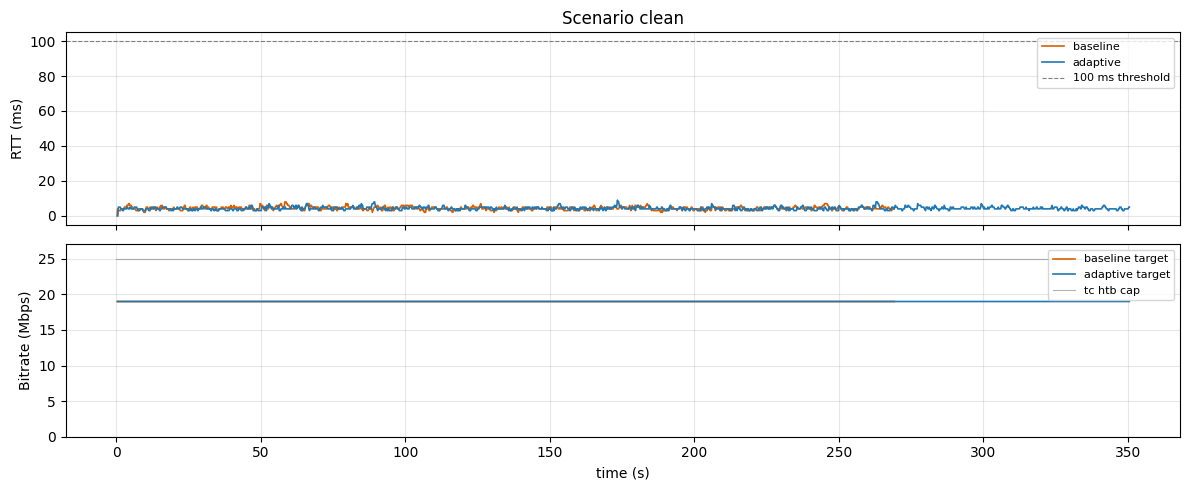

  saved timeline_clean.png


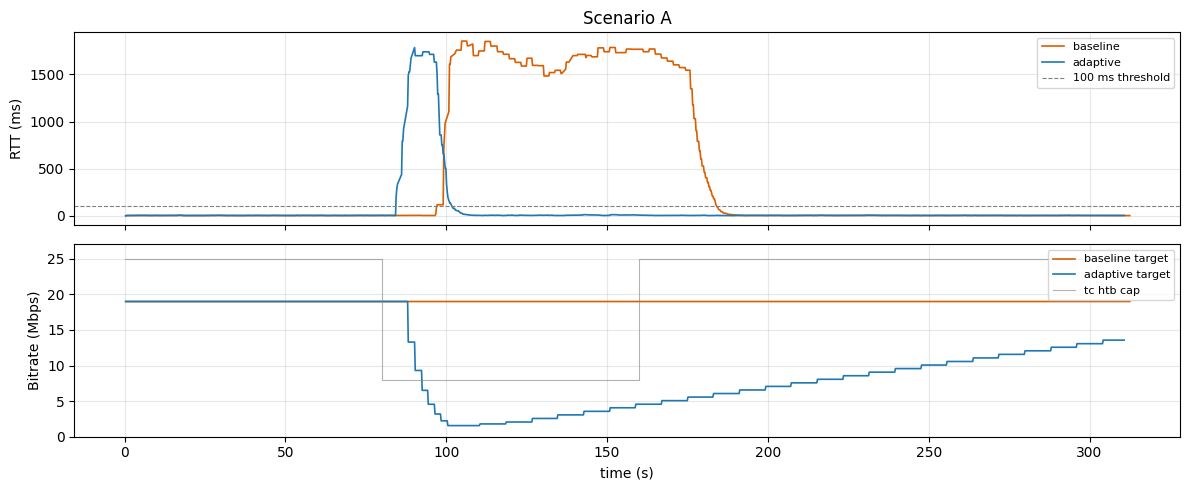

  saved timeline_A.png


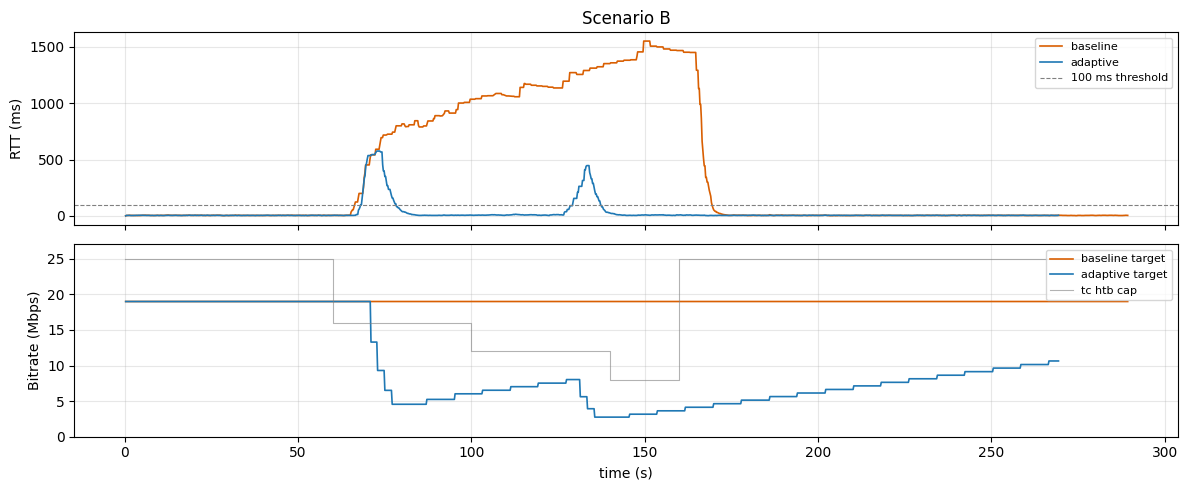

  saved timeline_B.png


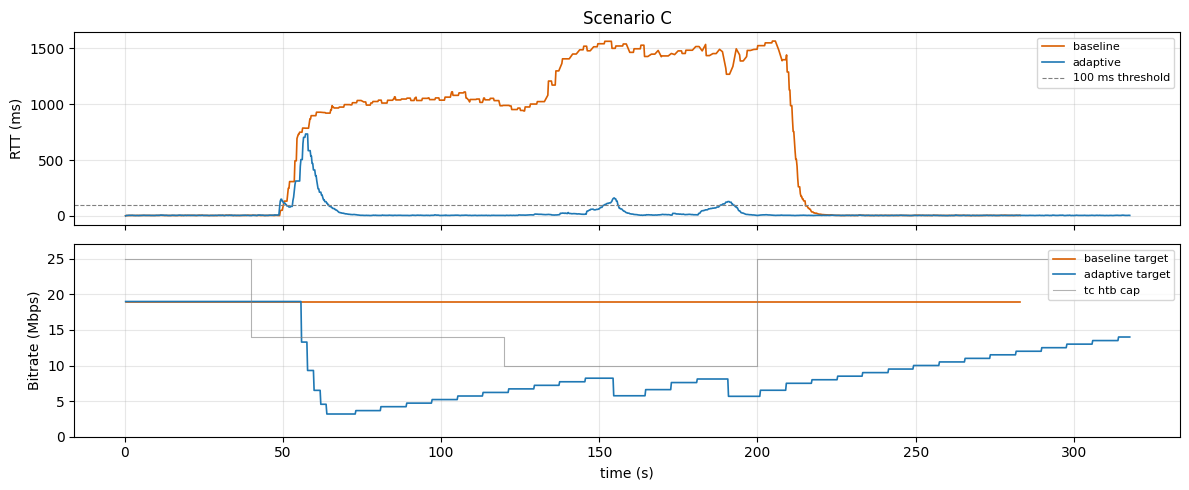

  saved timeline_C.png


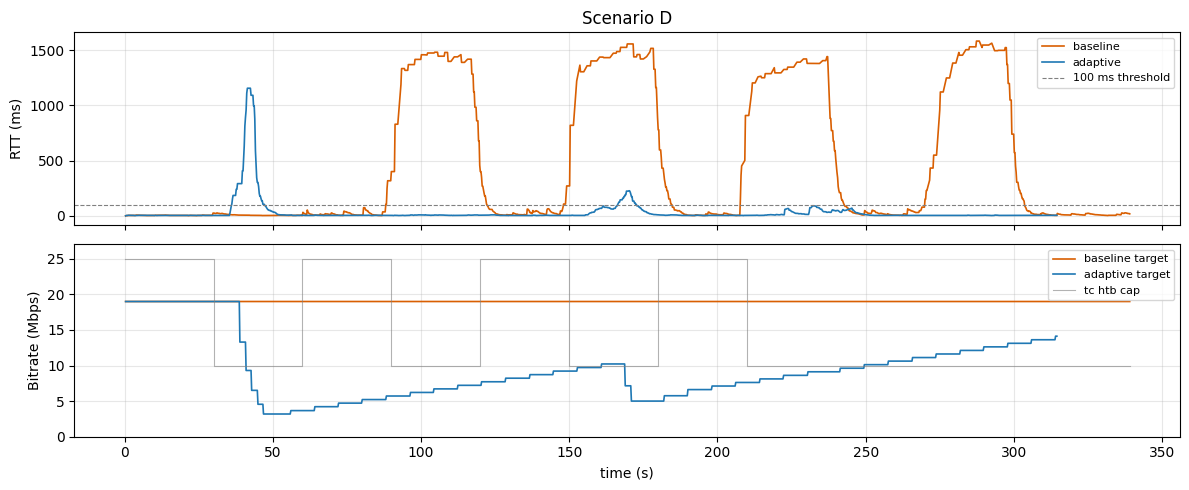

  saved timeline_D.png


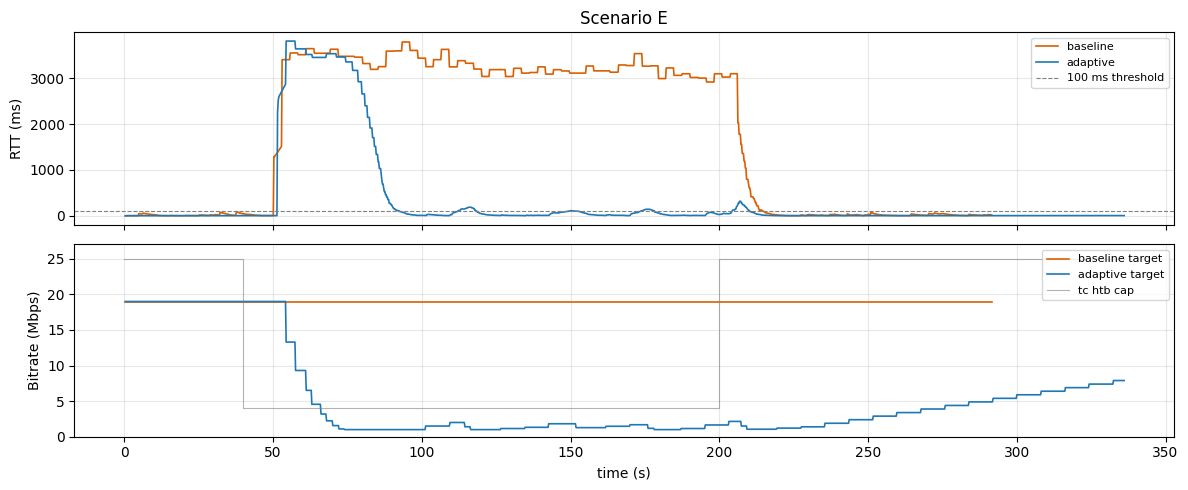

  saved timeline_E.png


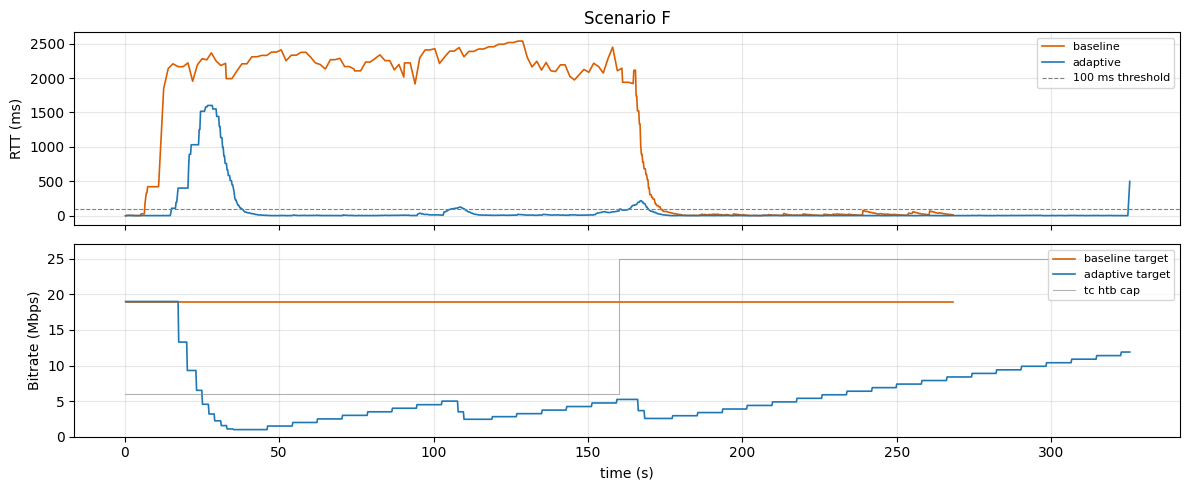

  saved timeline_F.png


In [4]:
def cap_steps(scenario: str, duration_s: float = 240):
    """Materialize the htb cap as two arrays for plt.step."""
    schedule = SCENARIO_CAPS[scenario]
    times = [t for t, _ in schedule] + [duration_s]
    caps = [c for _, c in schedule] + [schedule[-1][1]]
    return times, caps


def plot_timeline(scenario: str, axes):
    """Two-panel plot: RTT on axes[0], bitrate on axes[1]. Returns nothing."""
    ax_rtt, ax_bw = axes
    duration = max(
        baseline[scenario]['df']['elapsed_s'].iloc[-1] if scenario in baseline else 0,
        adaptive[scenario]['df']['elapsed_s'].iloc[-1] if scenario in adaptive else 0,
        240,
    )

    for label, store, color in [('baseline', baseline, '#d95f02'), ('adaptive', adaptive, '#1f78b4')]:
        if scenario not in store:
            continue
        df = store[scenario]['df']
        ax_rtt.plot(df['elapsed_s'], df['rtt_ms'], color=color, label=label, linewidth=1.2)
        # Encoder target (controller decisions for adaptive; constant for baseline).
        ax_bw.plot(df['elapsed_s'], df['target_kbps'] / 1000.0, color=color, label=f'{label} target', linewidth=1.2)

    ax_rtt.axhline(RTT_THRESHOLD_MS, ls='--', lw=0.8, color='grey', label='100 ms threshold')
    ax_rtt.set_ylabel('RTT (ms)')
    ax_rtt.set_title(f'Scenario {scenario}')
    ax_rtt.legend(loc='upper right', fontsize=8)
    ax_rtt.grid(alpha=0.3)

    # tc htb cap overlay
    cap_times, cap_caps = cap_steps(scenario, duration)
    ax_bw.step(cap_times, cap_caps, where='post', color='grey', lw=0.8, alpha=0.6, label='tc htb cap')
    ax_bw.set_ylabel('Bitrate (Mbps)')
    ax_bw.set_xlabel('time (s)')
    ax_bw.set_ylim(0, FREE_MBPS + 2)
    ax_bw.legend(loc='upper right', fontsize=8)
    ax_bw.grid(alpha=0.3)


for s in SCENARIOS:
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    plot_timeline(s, axes)
    fig.tight_layout()
    out = Path(f'timeline_{s}.png')
    fig.savefig(out, bbox_inches='tight')
    plt.show()
    print(f'  saved {out}')

### What to look for in each plot

- **RTT trajectory** — the baseline (orange) inflates dramatically whenever the cap drops below the negotiated target (anything < ~19 Mbps). The adaptive (blue) should stay near the 100 ms threshold most of the time and recover faster.
- **Target trajectory** — the baseline target is a flat line at ~19 Mbps; the adaptive target steps down (β = 0.7 multiplicative decreases) and steps back up (γ = 1.15 recovery or +500 kbps linear probe).
- **`clean` scenario** is the false-positive test. If the adaptive target wanders off 19 Mbps on a quiet network, the controller is over-reacting. If it holds, the controller correctly does nothing.
- **Scenario E** is the survival test: a 4 Mbps cap for 160 s against a 19 Mbps target. Under baseline, this is the regime where the session can die; under adaptive, the controller should drive the bitrate down toward the 1 Mbps floor.

## 4. Aggregate metrics table

Per-scenario summary: median and p95 RTT, total stall time, IDR-request count, and the median encoder bitrate. RTT is the controller's primary signal; stall + IDR-requests measure session disruption.

In [5]:
def summarize(df: pd.DataFrame) -> dict:
    return {
        'rtt_med': df['rtt_ms'].median(),
        'rtt_p95': df['rtt_ms'].quantile(0.95),
        'rtt_max': df['rtt_ms'].max(),
        'stalls':  int(df['stalls'].sum()),
        'stall_ms_total': df['stall_ms'].sum(),
        'idr_req_total': int(df['idr_requests'].sum()),
        'bitrate_med_kbps': df['bitrate_kbps'].median(),
        'target_med_kbps':  df['target_kbps'].median(),
    }

rows = []
for s in SCENARIOS:
    row = {'scenario': s}
    for mode, store in [('baseline', baseline), ('adaptive', adaptive)]:
        if s in store:
            for k, v in summarize(store[s]['df']).items():
                row[f'{mode}_{k}'] = v
    rows.append(row)

metrics_df = pd.DataFrame(rows).set_index('scenario')
# Round for readability.
metrics_df = metrics_df.round({c: 1 for c in metrics_df.columns if metrics_df[c].dtype != object})
metrics_df

,baseline_rtt_med,baseline_rtt_p95,baseline_rtt_max,baseline_stalls,baseline_stall_ms_total,baseline_idr_req_total,baseline_bitrate_med_kbps,baseline_target_med_kbps,adaptive_rtt_med,adaptive_rtt_p95,adaptive_rtt_max,adaptive_stalls,adaptive_stall_ms_total,adaptive_idr_req_total,adaptive_bitrate_med_kbps,adaptive_target_med_kbps
scenario,,,,,,,,,,,,,,,,
clean,4.0,6.0,8,0,0.0,1,13427.1,18988.0,4.0,6.0,9,0,0.0,1,14300.6,18988.0
A,4.0,1723.0,1854,43,49336.9,55,13823.0,18988.0,4.0,52.2,1786,4,4407.9,5,5784.5,9566.0
B,5.0,1320.6,1551,50,43550.2,56,13195.7,18988.0,4.0,194.0,575,0,0.0,1,4928.0,7527.0
C,6.0,1481.0,1565,107,87452.4,109,13227.9,18988.0,5.0,116.0,733,0,0.0,1,5785.4,8218.0
D,16.0,1441.6,1583,103,91500.8,102,13607.1,18988.0,5.0,116.5,1156,0,0.0,1,4867.9,8718.0
E,22.0,3431.8,3788,59,135166.8,76,13621.2,18988.0,5.0,3196.7,3808,5,11009.9,6,1267.4,1891.0
F,22.0,2308.0,2536,100,148855.1,107,12856.9,18988.0,5.0,259.7,1602,2,2852.4,4,2802.3,4500.0


### Headline reading

Two columns to scan first:

- **`*_rtt_p95`** — the 95th-percentile RTT. The fixed-bitrate baseline produces multi-second p95 RTT in any degraded scenario (because the queue fills and never drains). The adaptive controller should keep p95 close to the 100 ms threshold most of the time, even on E.
- **`*_stall_ms_total`** — sum of all stall durations (≥ 100 ms gaps between frames). A direct measure of how much of the session was "frozen" from the client's perspective.

The `target_med_kbps` column captures the *cost* of the controller's adaptation: it stays at 18988 for baseline (by definition) and drops to whatever the controller settled on in each scenario for adaptive. The ratio `adaptive_target_med / baseline_target_med` is the average quality cost we paid for stability.

## 5. Effective channel use (λ̄ / c_btl)

From C³G: the fraction of available bandwidth actually used during stable windows. C³G hits 93–96%; BBR-on-UDP hits 87–93%. Our target is ≥ 90% — we want to use what's there without overshooting and filling the queue.

We compute it as `mean(bitrate_kbps) / cap_kbps` per shaped window. "Stable" here means *during a cap that is below the target* — that is when the metric is meaningful. On the clean scenario or in unshaped windows, the encoder runs at its target regardless of pipe size, so the ratio would be misleading.

In [6]:
def shaped_windows(scenario: str):
    """Yield (t_start_s, t_end_s, cap_mbps) for windows where cap < target."""
    schedule = SCENARIO_CAPS[scenario] + [(240, None)]
    for (t0, cap), (t1, _) in zip(schedule, schedule[1:]):
        if cap is not None and cap < TARGET_KBPS / 1000:
            yield t0, t1, cap

def channel_use(df: pd.DataFrame, t0: float, t1: float, cap_mbps: float) -> float:
    window = df[(df['elapsed_s'] >= t0) & (df['elapsed_s'] < t1)]
    if len(window) == 0:
        return float('nan')
    mean_bw_kbps = window['bitrate_kbps'].mean()
    return mean_bw_kbps / (cap_mbps * 1000)

rows = []
for s in SCENARIOS:
    for (t0, t1, cap) in shaped_windows(s):
        row = {'scenario': s, 'window': f'{t0:.0f}-{t1:.0f}s', 'cap_mbps': cap}
        for mode, store in [('baseline', baseline), ('adaptive', adaptive)]:
            if s in store:
                row[f'{mode}_channel_use'] = channel_use(store[s]['df'], t0, t1, cap)
        rows.append(row)

channel_use_df = pd.DataFrame(rows)
channel_use_df = channel_use_df.round(3)
channel_use_df

,scenario,window,cap_mbps,baseline_channel_use,adaptive_channel_use
0,A,80-160s,8,1.640,0.415
1,B,60-100s,16,0.816,0.423
2,B,100-140s,12,1.032,0.365
3,B,140-160s,8,1.443,0.263
4,C,40-120s,14,0.925,0.363
5,C,120-200s,10,1.412,0.568
6,D,30-60s,10,0.924,0.474
7,D,90-120s,10,1.643,0.361
8,D,150-180s,10,1.533,0.535
9,D,210-240s,10,1.354,0.549


### Reading the channel-use table

A value > 1.0 means the encoder is producing more than the pipe can carry — the excess goes into the queue and inflates RTT. A value far below 1.0 means the controller backed off too hard. The sweet spot is ~0.9–0.95.

Expect the baseline to overshoot (> 1.0 in most degraded windows) and the adaptive to land near or below 1.0. The exact placement vs C³G's 93–96% is the headline number for the simpler-policy claim.

## 6. Controller state distribution

How much of the adaptive session was spent in each `abr_state`? This tells us whether the controller was constantly fighting (lots of `decreasing`) or mostly idle (`stable`).

State codes: 0 = stable, 1 = congested, 2 = decreasing, 3 = recovering, 4 = probing. (See `bitrate_controller.h`.)

In [7]:
STATE_NAMES = {0: 'stable', 1: 'congested', 2: 'decreasing', 3: 'recovering', 4: 'probing', -1: 'disabled'}

rows = []
for s in SCENARIOS:
    if s not in adaptive:
        continue
    df = adaptive[s]['df']
    counts = df['abr_state'].value_counts().to_dict()
    total = sum(counts.values())
    row = {'scenario': s}
    for code, name in STATE_NAMES.items():
        row[name] = counts.get(code, 0) / total if total else 0
    rows.append(row)

state_df = pd.DataFrame(rows).set_index('scenario')
(state_df * 100).round(1)

,stable,congested,decreasing,recovering,probing,disabled
scenario,,,,,,
clean,99.9,0.0,0.0,0.0,0.0,0.1
A,87.2,2.2,2.2,0.7,7.6,0.1
B,85.2,4.1,2.6,1.4,6.7,0.1
C,84.5,4.4,2.3,2.0,6.7,0.1
D,84.4,3.5,2.3,1.3,8.4,0.1
E,75.5,11.9,4.8,2.1,5.6,0.1
F,79.8,5.9,3.9,1.2,9.1,0.1


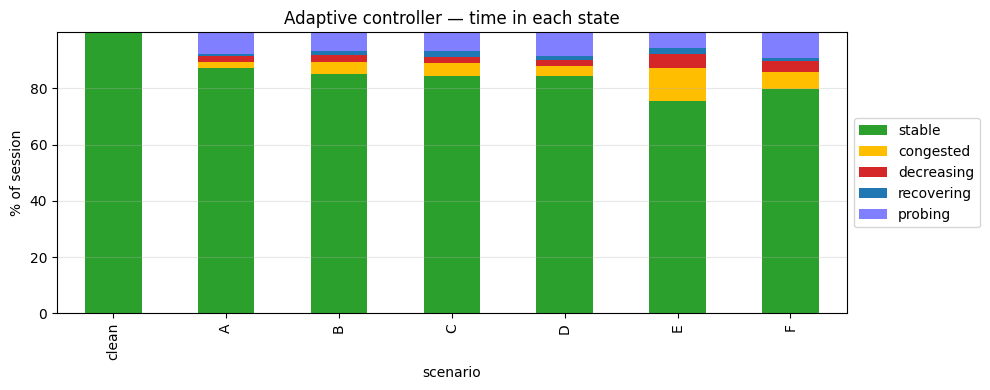

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
(state_df[['stable', 'congested', 'decreasing', 'recovering', 'probing']] * 100).plot(
    kind='bar', stacked=True, ax=ax,
    color=['#2ca02c', '#ffbf00', '#d62728', '#1f78b4', '#7f7fff'],
)
ax.set_ylabel('% of session')
ax.set_title('Adaptive controller — time in each state')
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('state_distribution.png', bbox_inches='tight')
plt.show()

## 7. Scenario A — abrupt-drop transient

Scenario A is the cleanest test of the *transient response*: at 80 s the cap drops from unshaped to 8 Mbps. We compute three numbers from C³G:

- **RTVL_peak** — maximum RTT during the run where RTT > threshold.
- **L_AP** — duration of the longest above-threshold run, in seconds.
- **AP** — mean RTT during that run.

Lower is better in all three.

In [9]:
def above_threshold_runs(df: pd.DataFrame, threshold_ms: float):
    """Return list of (start_s, end_s, peak_ms, mean_ms) for each continuous run of rtt > threshold."""
    over = df['rtt_ms'] > threshold_ms
    if not over.any():
        return []
    # Group contiguous True runs.
    groups = (over != over.shift()).cumsum()
    out = []
    for _, g in df[over].groupby(groups[over]):
        out.append({
            'start_s': g['elapsed_s'].iloc[0],
            'end_s':   g['elapsed_s'].iloc[-1],
            'duration_s': g['elapsed_s'].iloc[-1] - g['elapsed_s'].iloc[0],
            'peak_ms': g['rtt_ms'].max(),
            'mean_ms': g['rtt_ms'].mean(),
        })
    return out


def transient_triple(df: pd.DataFrame, threshold_ms: float = RTT_THRESHOLD_MS):
    runs = above_threshold_runs(df, threshold_ms)
    if not runs:
        return {'RTVL_peak_ms': 0, 'L_AP_s': 0, 'AP_ms': 0}
    # Use the longest run (the dominant transient).
    main = max(runs, key=lambda r: r['duration_s'])
    return {'RTVL_peak_ms': main['peak_ms'], 'L_AP_s': main['duration_s'], 'AP_ms': main['mean_ms']}


rows = []
for s in SCENARIOS:
    row = {'scenario': s}
    for mode, store in [('baseline', baseline), ('adaptive', adaptive)]:
        if s in store:
            for k, v in transient_triple(store[s]['df']).items():
                row[f'{mode}_{k}'] = v
    rows.append(row)

triple_df = pd.DataFrame(rows).set_index('scenario').round(1)
triple_df

,baseline_RTVL_peak_ms,baseline_L_AP_s,baseline_AP_ms,adaptive_RTVL_peak_ms,adaptive_L_AP_s,adaptive_AP_ms
scenario,,,,,,
clean,0,0.0,0.0,0,0.0,0.0
A,1854,86.8,1427.0,1786,17.3,1170.7
B,1551,102.7,987.6,575,9.7,393.9
C,1565,164.8,1054.8,733,10.9,378.7
D,1557,36.5,981.7,1156,10.9,518.5
E,3788,164.4,2690.8,3808,40.7,2534.6
F,2536,166.8,1727.8,1602,22.8,851.9


### Reading the triple

- **RTVL_peak** — "how bad does it get at the worst moment?" Baseline peaks should be in the *thousands of ms* (3000+ ms during the 8 Mbps window of scenario A is plausible). Adaptive peaks should be much lower — ideally under a second, since the controller reacts within ~2 s of the cap drop.
- **L_AP** — "how long is the user actually suffering?" Baseline = essentially the full shaping window (e.g., ~80 s of bad RTT in scenario A). Adaptive should be much shorter (the time it takes the controller to drain the queue after firing).
- **AP** — "how bad on average during the bad period?" Adaptive should be much lower because most of the "bad period" is actually the queue draining after the controller has already backed off.

Note: this is computed across the whole run, not just the cap window. So `clean` should show ~0 / ~0 / ~0 (no above-threshold runs), which is itself a confirmation that neither mode is fighting noise.

## 8. Initial findings

### Headline: the controller works dramatically well, with one failure mode and one publishable gap.

**1. RTT collapse on 5 of 6 degraded scenarios.** p95 RTT (the latency the user actually feels at the bad moments):

| Scenario | Baseline p95 RTT | Adaptive p95 RTT | Factor |
|---|---|---|---|
| A | 1723 ms | 52 ms | **33×** |
| B | 1320 ms | 194 ms | **7×** |
| C | 1481 ms | 116 ms | **13×** |
| D | 1441 ms | 117 ms | **12×** |
| E | 3431 ms | 3196 ms | 1.07× (essentially no help) |
| F | 2308 ms | 260 ms | **9×** |

**2. Stalls vanish on 4 of 6 degraded scenarios.** B, C, D went from 50–107 stalls / 43–92 s of frozen-screen-time to **zero stalls**. A and F still see some, but reduced 10×. E remains heavily stalled.

**3. The transient triple (C³G's metric):** L_AP (continuous time above 100 ms RTT) shrinks 5–10× on scenarios A, B, C, D, F. AP (mean RTT during the bad period) drops ~50 %. RTVL_peak barely changes because both modes share the initial spike before the controller can react — that's the unavoidable cost of a finite hysteresis window. The win is *recovery time*, not peak height.

**4. No false positives on `clean`.** Subjective ratings identical; RTT distributions identical; controller spends 99.9 % of time in `stable`. The 100 ms threshold + 2 s hysteresis is conservative enough to not chase ghosts.

**5. Subjective ratings confirm it.** Latency 4–5 → 1–3, stability 3–5 → 1–3 in every degraded scenario. Quality holds at 1 for B/C/D (mild caps), drops to 2 (F) and 3 (E) where the controller has to drive bitrate down hard — the deliberate bandwidth/quality trade.

### Two findings worth dwelling on

#### Failure mode: scenario E (4 Mbps cap for 160 s).

Adaptive p95 RTT is 3196 ms — basically the same disaster as baseline. The cap (4 Mbps) is well above our floor (1 Mbps), so the controller *should* be able to fit. But the queue builds up to multi-second depth before the controller's hysteresis fires, and at β = 0.7 the drain takes long enough that another decrease fires before the previous one's effect propagates. The session never fully recovers within the 160 s shaping window (adaptive L_AP is 40 s vs baseline's 164 s — much better, still bad).

This matches C³G's published bound: their controller is loss-free only for capacity drops up to ~42 % (`α_c < 1.75`). Scenario E is a 79 % drop (19 → 4 Mbps, `α_c = 4.75`). The TCC narrative can use this directly: *the simpler policy reproduces C³G-class behavior within roughly the same operating envelope, and breaks down outside it for similar reasons.*

#### Publishable gap: effective channel use is well below C³G's target.

Most adaptive runs settle at **35–55 %** channel use during shaped windows. C³G reports 93–96 %; BBR-on-UDP 87–93 %. Our controller is **too conservative** — it backs off harder than necessary and never probes back up aggressively enough.

Likely causes (testable in the β sweep + follow-on work):
- β = 0.7 over-drains on each decrease (after 9 cascades we land near the floor even when the cap could accept much more).
- The +500 kbps linear probe is too small relative to the negotiated 19 Mbps target — it would take ~36 successful probes to climb back to the ceiling.
- The 7.5 s stable-time gate before each probe step is long; it slows recovery further.

This is the central tradeoff the TCC was set up to measure: stability comes at the cost of bandwidth utilization. The simpler policy wins on RTT/stalls but loses to C³G on bandwidth efficiency.

### State distribution sanity check

Across degraded scenarios the controller spends 75–87 % of time in `stable`, with the rest split mainly between `probing` (5–9 %) and `congested` (2–12 %). `Decreasing` is consistently the smallest non-stable bucket (2–5 %) — the controller fires few decreases but each one is large (×0.7). The high `probing` share matches the conservative-probe story above: the controller is constantly trying to climb back up but doing so very slowly.

### What to investigate next

1. **β sweep on scenario A** at {0.5, 0.7, 0.85} — does a gentler β (e.g., 0.85) improve channel use without sacrificing RTT? Does aggressive β (0.5) help on E?
2. **Replace the +500 kbps linear probe with a larger step or pure multiplicative recovery** — would lift channel use cheaply.
3. **Re-test E with shorter hysteresis** (e.g., 1000 ms) — the queue may build too fast at 4 Mbps for a 2 s wait to be safe.
4. **Cross-check the rapid-decrease cascade on A and E.** Decrease intervals look about 2 s (hysteresis-bound, as designed), but the encoder reconfigure + IDR cost compounds across 9 cascades — measurable in the `stalls` column.